# Fine-tuning BERT for text classification quest

**Увага**: Тренування моделі буде значно швидшим на GPU. Активуйте його в Colab (Runtime -> Change runtime type -> A100 або L4 GPU)

Ставимо пакет курсу та бібліотеки: `datasets` для даних, `transformers` і `accelerate` для моделі й тренування, `scikit-learn` для метрик і бейзлайну.

In [ ]:
!pip install --quiet --ignore-installed https://static.lp-nlp.com/pypi/lpnlp-2026.11.2-py3-none-any.whl requests==2.32.4
!pip install --quiet -U datasets accelerate transformers scikit-learn
# flash-attn не встановлюємо: на T4 він не підтримується, а збірка займає дуже довго

ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
cudf-cu13 26.6.0 requires pyarrow<24,>=19.0.0, but you have pyarrow 26.0.1 which is incompatible.


Перевіряємо GPU і стартуємо квест. Сервер видає датасет; на GPU беремо більше прикладів, щоб модель вийшла точнішою.

In [ ]:
import torch
print("GPU:", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "немає")

import lpnlp

lab = lpnlp.start(
    email="roman.mydzhyn@example.com",
    lab="quest_text_classification",
    size=10000 if torch.cuda.is_available() else 2000,   # більше даних -> якісніша модель -> чіткіший малюнок
    )

GPU: Tesla T4
Удачі!


Дивимось, які файли видав сервер: train/valid/test тексти, мітки й metadata (палітра для малюнка).

In [ ]:
# Це завдання містить тренувальні, валідаційні та тестові дані
# В тестових даних закодовано малюнок, який можна побачити
# при достатньо якісній моделі

# Список наявних файлів:
sorted(lab.files.keys())

['metadata.json',
 'test.txt',
 'train.labels',
 'train.txt',
 'valid.labels',
 'valid.txt']

Розбиваємо файли на списки рядків і перемішуємо train. Тест не перемішуємо, бо порядок прикладів у ньому і є порядком пікселів малюнка.

In [ ]:
# Розіб'ємо файли на рядки для зручності
import json
from sklearn.utils import shuffle

train_X = lab.files["train.txt"].splitlines()
train_y = lab.files["train.labels"].splitlines()
train_X, train_y = shuffle(train_X, train_y, random_state=42)
valid_X = lab.files["valid.txt"].splitlines()
valid_y = lab.files["valid.labels"].splitlines()
test_X = lab.files["test.txt"].splitlines()
meta = json.loads(lab.files["metadata.json"])

Розміри вибірок і кілька прикладів текстів.

In [ ]:
# Приклади вхідних текстів
print(len(train_X), len(valid_X), len(test_X))
train_X[:3]

10000 1000 9216


["I never thought Fox did a stellar job of putting LIS on DVD, however this volume is by far the worse I've seen. The transfer is bad enough to ruin your viewing experience. SAVE YOUR HARD EARNED MONEY!This is a great series. It's just a very bad transfer for this specific volume.",
 "After reading some of the other reviews of this book, I have to wonder if they were looking at the same book! I found this volume hugely disappointing, so much so that I returened it the very next day for a refund. There are models that are so fat that you can't find their belly-buttons, models with bruises on thier legs, all lit to look like medical specimens. If that's your cup of tea, then this book is for you. To me it looked like a collection of the photographs that would normally be edited from a book of this sort.",
 'This little book collects 125 (orthodox) chess problems/puzzles/brain-teasers. Each of them was extracted from actual game play in history. Every problem has a chess diagram and comes

Скільки прикладів кожного класу. Перевіряємо, чи класи збалансовані.

In [ ]:
# ...та класів до них
from collections import Counter
print(Counter(train_y))
train_y[:3]

Counter({'1': 5016, '0': 4984})


['0', '0', '1']

Пакуємо дані у `DatasetDict`, бо саме такий формат розуміє `Trainer` з `transformers`.

In [ ]:
# Для подальшого тренування сконвертуємо датасет в формат,
# який очікує бібліотека transformers
import datasets

dataset = datasets.DatasetDict({
    "train": datasets.Dataset.from_dict({
        "text": train_X,
        "label": [int(y) for y in train_y],
    }),
    "validation": datasets.Dataset.from_dict({
        "text": valid_X,
        "label": [int(y) for y in valid_y],
    }),
    "test": datasets.Dataset.from_dict({
        "text": test_X,
    }),
})

Допоміжна функція: кожне передбачення стає одним пікселем квадратного зображення.

In [ ]:
# Допоміжна функція

from PIL import Image
import math
import json

def predictions_to_image(predictions, meta):
    """Малює по одному пікселю на кожне передбачення.

    Args:
      predictions: list of ints or strings (class labels)
      meta: dataset metadata (dict)
    """

    labels = sorted(set(predictions))
    image_size = int(math.sqrt(len(predictions)))
    image = Image.new("P", (image_size, image_size))
    image.putpalette(meta["palette"])
    image.putdata([labels.index(prediction) for prediction in predictions])

    image = image.convert("RGB")
    return image



# Тренування моделі

Ми вже бачили класифікатори на логістичній регресії, які використовували мішок слів та мішок ембедингів. Тепер дотренуємо BERT або його більш сучасну версію (ModernBERT, Etin) за допомогою бібліотеки HuggingFace transformers.

Корисні посилання:
- https://www.philschmid.de/fine-tune-modern-bert-in-2025
- https://huggingface.co/learn/llm-course/chapter3

Також розпитуйте свою LLM, щоб зрозуміти, що відбувається.

Головне: fine-tuning трансформера. По кроках:
1. **Модель.** Якщо тексти кирилицею, беремо мультимовну XLM-RoBERTa, інакше ModernBERT.
2. **Токенізація.** Дивимось довжини текстів у токенах і обрізаємо до `MAX_LEN = 256` (truncation).
3. **`AutoModelForSequenceClassification`.** Це претренований енкодер, до якого додано нову «голову»: лінійний шар на `num_labels` класів.
4. **Метрики:** accuracy і F1 macro на валідації.
5. **`TrainingArguments`:** lr 2e-5 (мале, щоб не зіпсувати претреновані знання), 2 епохи, batch 16, warmup 100 кроків, weight decay 0.01, fp16 на GPU.
6. **`Trainer`** сам крутить цикл навчання. `DataCollatorWithPadding` вирівнює довжини в батчі.
У результаті маємо accuracy ≈ 0.96 на валідації.

In [ ]:
import re, time, numpy as np
from transformers import (AutoTokenizer, AutoModelForSequenceClassification, TrainingArguments,
                          Trainer, DataCollatorWithPadding, pipeline)
from sklearn.metrics import accuracy_score, f1_score

# Якщо тексти українською (кирилиця) -- беремо мультимовну XLM-RoBERTa, інакше ModernBERT
cyr = sum(bool(re.search("[а-яіїєґ]", t.lower())) for t in train_X[:200])
MODEL = "FacebookAI/xlm-roberta-base" if cyr > 100 else "answerdotai/ModernBERT-base"
print("Модель:", MODEL)

tokenizer = AutoTokenizer.from_pretrained(MODEL)
lengths = [len(tokenizer(t)["input_ids"]) for t in train_X[:500]]
print("Довжина в токенах: медіана", int(np.median(lengths)), "95%", int(np.percentile(lengths, 95)))
MAX_LEN = 256

def tokenize(batch):
    return tokenizer(batch["text"], truncation=True, max_length=MAX_LEN)

tokenized = dataset.map(tokenize, batched=True)

labels = sorted(set(int(y) for y in train_y))
model = AutoModelForSequenceClassification.from_pretrained(
    MODEL, num_labels=len(labels),
    id2label={i: str(i) for i in labels}, label2id={str(i): i for i in labels})

def compute_metrics(eval_pred):
    logits, y = eval_pred
    pred = logits.argmax(-1)
    return {"accuracy": accuracy_score(y, pred), "f1": f1_score(y, pred, average="macro")}

args = TrainingArguments(
    output_dir="bert-quest",
    per_device_train_batch_size=16,
    per_device_eval_batch_size=64,
    learning_rate=2e-5,
    num_train_epochs=2,
    weight_decay=0.01,
    warmup_steps=100,
    fp16=torch.cuda.is_available(),
    eval_strategy="epoch",
    save_strategy="no",
    logging_steps=50,
    report_to="none",
)
trainer = Trainer(model=model, args=args, train_dataset=tokenized["train"],
                  eval_dataset=tokenized["validation"],
                  data_collator=DataCollatorWithPadding(tokenizer), compute_metrics=compute_metrics)
t0 = time.time()
trainer.train()
bert_train_time = time.time() - t0
print(f"Час тренування: {bert_train_time/60:.1f} хв")
print(trainer.evaluate())

Модель: answerdotai/ModernBERT-base


config.json:   0%|          | 0.00/1.19k [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/20.8k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/2.13M [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/694 [00:00<?, ?B/s]

Довжина в токенах: медіана 85 95% 204


... (7 outputs left out)

Epoch,Training Loss,Validation Loss,Accuracy,F1
1,0.160289,0.114604,0.961000,0.960898
2,0.054730,0.145104,0.962000,0.961933


Час тренування: 6.4 хв


Training Loss,Validation Loss,Epoch,Accuracy,F1
0.054730,0.145104,2,0.962000,0.961933


{'eval_loss': 0.1451036036014557, 'eval_accuracy': 0.962, 'eval_f1': 0.9619328495466002}


## Тест

В тестових даних закодовано малюнок. Кожен позитивний відгук стає білим пікселем, а негативний -- чорним.

Якщо ваша модель натренована достатньо якісно, то малюнок можна розгледіти.

Відповідь на це завдання -- що зображено на малюнку? (одним словом, українською або англійською)

Робимо передбачення для тесту через `pipeline` і малюємо з них картинку: позитивний відгук дає білий піксель, негативний чорний. Якщо модель якісна, малюнок видно чітко.

Передбачення 9216 текстів: 65.6 c


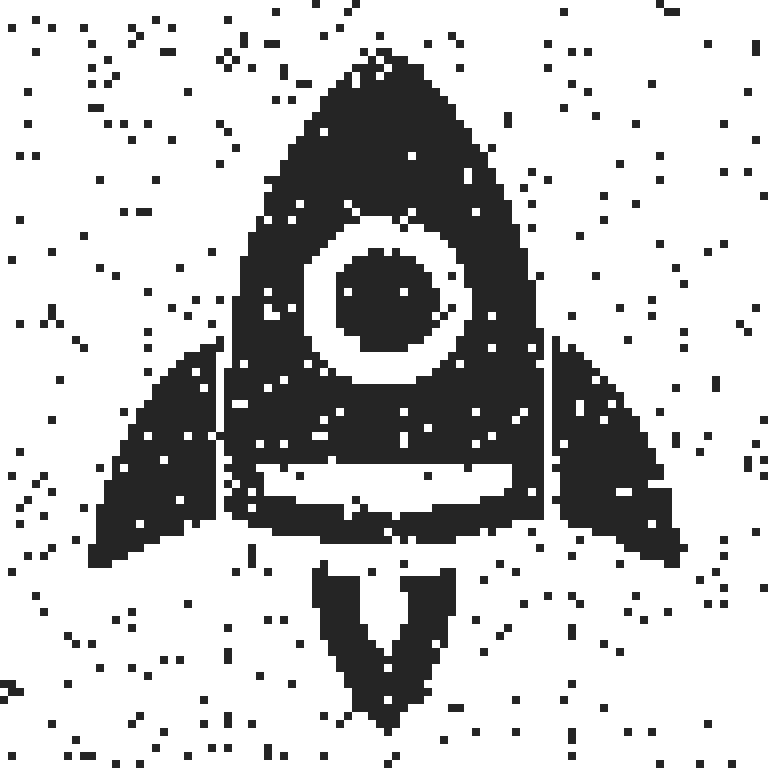

In [10]:
classifier = pipeline("text-classification", model=trainer.model, tokenizer=tokenizer,
                      device=0 if torch.cuda.is_available() else -1, truncation=True, max_length=MAX_LEN)
t0 = time.time()
predictions = [int(y["label"]) for y in classifier(test_X, batch_size=64)]
bert_pred_time = time.time() - t0
print(f"Передбачення {len(test_X)} текстів: {bert_pred_time:.1f} c")

image = predictions_to_image(predictions, meta)
image.save("quest_image.png")
display(image.resize((image.width * 8, image.height * 8), resample=0))

На малюнку ракета. Відправляємо відповідь «rocket».

In [13]:
lab.answer("rocket")  # На малюнку ракета

Відповідь правильна ✅
Вірно! 🚀 Лаба зараховується.


# Додаткове завдання (не обовʼязкове)

Натренуйте простий класифікатор на логістичній регресії. Наскільки відрізняється якість від BERT або ModernBERT? Швидкість тренування? Швидкість передбачення?

Додаткове завдання: бейзлайн TF-IDF + логістична регресія. TF-IDF перетворює текст на вектор ваг слів і біграм, а LogReg вчиться розділяти класи. Порівнюємо з трансформером: LogReg тренується за секунди, але дає accuracy ≈ 0.87 проти ≈ 0.96, і її малюнок помітно «шумніший». Причина в тому, що TF-IDF не бачить порядку слів і контексту (заперечення, сарказм), а BERT бачить.

,accuracy (valid),F1 macro (valid),"тренування, с","передбачення test, с"
answerdotai/ModernBERT-base,0.962,0.962,382.746,65.594
TF-IDF + LogisticRegression,0.865,0.865,3.701,1.165


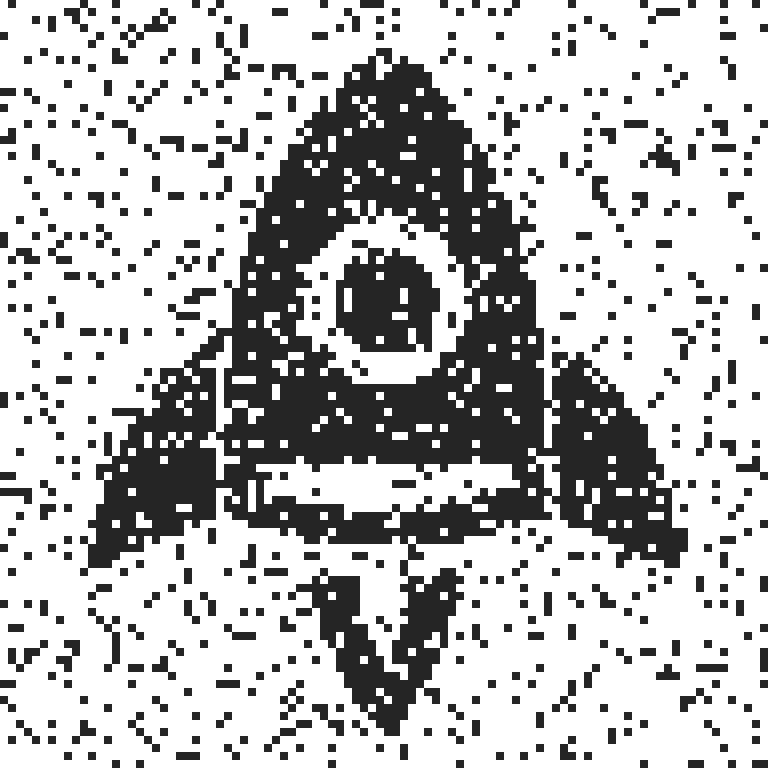

In [12]:
# Логістична регресія на TF-IDF для порівняння
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression

t0 = time.time()
vec = TfidfVectorizer(ngram_range=(1, 2), min_df=2, sublinear_tf=True)
Xtr = vec.fit_transform(train_X)
lr = LogisticRegression(max_iter=2000, C=4).fit(Xtr, [int(y) for y in train_y])
lr_train_time = time.time() - t0
t0 = time.time()
lr_valid = lr.predict(vec.transform(valid_X))
lr_test = lr.predict(vec.transform(test_X))
lr_pred_time = time.time() - t0
yv = [int(y) for y in valid_y]
bert_valid = [int(y["label"]) for y in classifier(valid_X, batch_size=64)]

import pandas as pd
display(pd.DataFrame({
    "accuracy (valid)": [accuracy_score(yv, bert_valid), accuracy_score(yv, lr_valid)],
    "F1 macro (valid)": [f1_score(yv, bert_valid, average="macro"), f1_score(yv, lr_valid, average="macro")],
    "тренування, с": [bert_train_time, lr_train_time],
    "передбачення test, с": [bert_pred_time, lr_pred_time],
}, index=[MODEL, "TF-IDF + LogisticRegression"]).round(3))

lr_image = predictions_to_image(list(lr_test), meta)
display(lr_image.resize((lr_image.width * 8, lr_image.height * 8), resample=0))